<a href="https://colab.research.google.com/github/daqhi/enrico_test/blob/master/enrico_ui_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Install libraries

!pip install torch torchvision pandas matplotlib seaborn scikit-learn pillow


In [3]:
# import libraries

import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from collections import Counter

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


PyTorch version: 2.11.0+cu130
GPU available: True




* torch: Deep learning framework
* pandas: Working with dataset information.
* matplotlib and seaborn: Visualizing data.
* PIL: Opening and processing images.
* torch.cuda: Checking whether your GPU is available.



In [7]:
# mount G-Drive

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
# set dataset path

dataset_path = "/content/drive/MyDrive/enrico"

In [10]:
# inspect files

for root, dirs, files in os.walk(dataset_path):
    print("Folder:", root)
    print("Subfolders:", dirs[:10])
    print("Number of files:", len(files))
    break

Folder: /content/drive/MyDrive/enrico
Subfolders: []
Number of files: 0


Image dimensions: (946, 2047)
Image format: JPEG


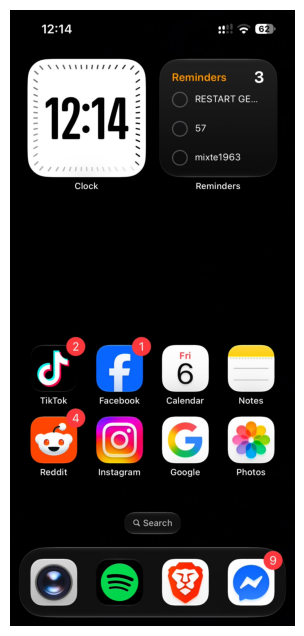

In [11]:
# display a mobile UI screenshot

image_path = "/content/drive/MyDrive/enrico/pic1.jpg"

img = Image.open(image_path)

print("Image dimensions:", img.size)
print("Image format:", img.format)

plt.figure(figsize=(5, 8))
plt.imshow(img)
plt.axis("off")
plt.show()


Questions to ask yourself:
1. What is the image resolution?
2. Are all screenshots the same dimensions?
3. Are the screenshots RGB or grayscale?
4. Are there images with unusual dimensions?
5. What visual characteristics distinguish one UI category from another?
These observations will help you decide how to preprocess the images.

In [16]:
# download Enrico GitHub Repo

import os

repo_path = "/content/enrico"

if not os.path.exists(repo_path):
    !git clone https://github.com/luileito/enrico.git

print("Repository downloaded:", os.path.exists(repo_path))

Repository downloaded: True


In [17]:
# load the labels

import os

zip_path = "/content/screenshots.zip"
image_dir = "/content/enrico_screenshots"

if not os.path.exists(zip_path):
    !wget -O /content/screenshots.zip https://userinterfaces.aalto.fi/enrico/resources/screenshots.zip

if not os.path.exists(image_dir):
    !unzip -q /content/screenshots.zip -d /content/enrico_screenshots

print("Screenshots extracted:", os.path.exists(image_dir))

Screenshots extracted: True


In [19]:
# load and inspect the labels

labels_path = "/content/enrico/design_topics.csv"

df = pd.read_csv(labels_path)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (1460, 2)

First 5 rows:


,screen_id,topic
0,50245,tutorial
1,320,list
2,39729,login
3,8555,form
4,39305,list



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   screen_id  1460 non-null   int64 
 1   topic      1460 non-null   object
dtypes: int64(1), object(1)
memory usage: 22.9+ KB


In [20]:
# locate the screenshot files

from glob import glob

image_files = glob(
    "/content/enrico_screenshots/**/*.jpg",
    recursive=True
)

print("Number of JPG images:", len(image_files))

# Create a dictionary using image filenames
image_lookup = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_files
}

# Match screen IDs with image paths
df["image_path"] = df["screen_id"].astype(str).map(image_lookup)

print("Matched images:", df["image_path"].notna().sum())
print("Missing images:", df["image_path"].isna().sum())

display(df.head())


Number of JPG images: 1460
Matched images: 1460
Missing images: 0


,screen_id,topic,image_path
0,50245,tutorial,/content/enrico_screenshots/screenshots/50245.jpg
1,320,list,/content/enrico_screenshots/screenshots/320.jpg
2,39729,login,/content/enrico_screenshots/screenshots/39729.jpg
3,8555,form,/content/enrico_screenshots/screenshots/8555.jpg
4,39305,list,/content/enrico_screenshots/screenshots/39305.jpg


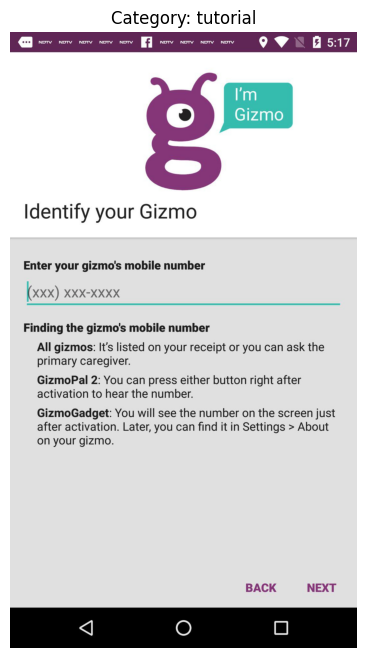

Screen ID: 50245
Image dimensions: (1080, 1920)
Image format: JPEG


In [22]:
# display an actual screenshot

sample = df.dropna(subset=["image_path"]).iloc[0]

img = Image.open(sample["image_path"])

plt.figure(figsize=(5, 8))
plt.imshow(img)
plt.title(f"Category: {sample['topic']}")
plt.axis("off")
plt.show()

print("Screen ID:", sample["screen_id"])
print("Image dimensions:", img.size)
print("Image format:", img.format)

Number of unique categories: 20


,Number of Screenshots
topic,
list,265
tutorial,163
gallery,144
login,141
form,103
settings,90
menu,79
bare,76
modal,67


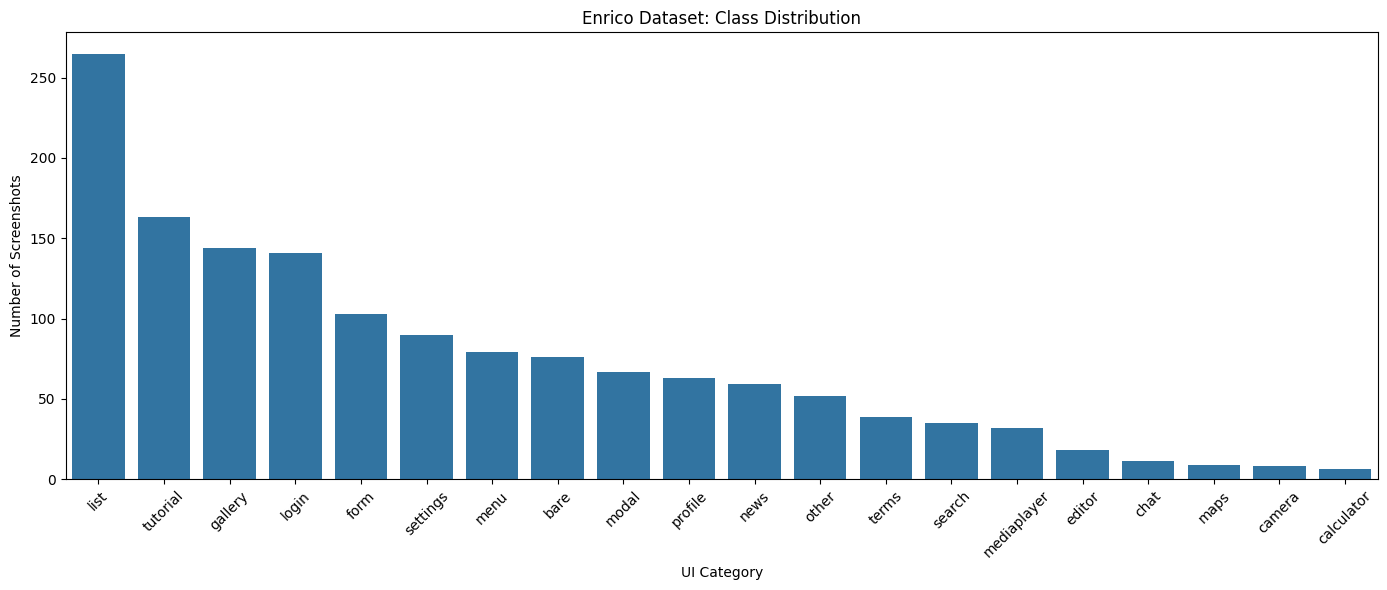

In [23]:
# analyze the class distribution

class_counts = df["topic"].value_counts()

print("Number of unique categories:", df["topic"].nunique())
display(class_counts.to_frame("Number of Screenshots"))

plt.figure(figsize=(14, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Enrico Dataset: Class Distribution")
plt.xlabel("UI Category")
plt.ylabel("Number of Screenshots")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()